# PowerPoint

You will build: a three-slide quarterly review deck with a diagram and an editable equation, then open a deck
made in PowerPoint.

Run it from this folder with ``python powerpoint.py``, or open ``powerpoint.ipynb``. Saving ``.pptx`` needs
the office extra: ``pip install "pysvgwriter[office]"``.

In [1]:
import svgwriter as svg

A slide is a document. The theme gives every slide the same look, and each shape stays editable in PowerPoint.

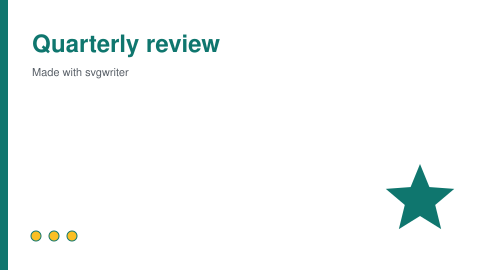

In [2]:
WIDTH, HEIGHT = 480, 270
THEME = "light"


def slide(title: str, subtitle: str) -> svg.Document:
    """An empty slide with a title and a subtitle."""
    doc = svg.Document(WIDTH, HEIGHT, theme=THEME)
    doc.rect(0, 0, WIDTH, HEIGHT).as_role("background")
    doc.rect(0, 0, 8, HEIGHT).as_role("shape")
    doc.text(title, x=32, y=52).as_role("title")
    doc.text(subtitle, x=32, y=76).as_role("caption")
    return doc


cover = slide("Quarterly review", "Made with svgwriter")
cover += svg.paths.star(420, 200, 36, 16)
for index in range(3):
    cover += svg.paths.dot(36 + index * 18, 236, 5)
cover

A diagram slide: boxes, labels and arrows from the theme roles.

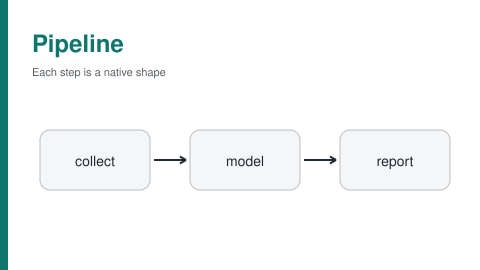

In [3]:
flow = slide("Pipeline", "Each step is a native shape")
for index, label in enumerate(("collect", "model", "report")):
    x = 40 + index * 150
    flow.rect(x, 130, 110, 60, rx=10).as_role("box")
    flow.text(label, x=x + 55, y=166, text_anchor="middle").as_role("text")
    if index:
        flow += svg.paths.arrow(x - 36, 160, x - 4, 160, head=7)
flow

A formula from `svg.latex` becomes a real PowerPoint equation you can still edit.

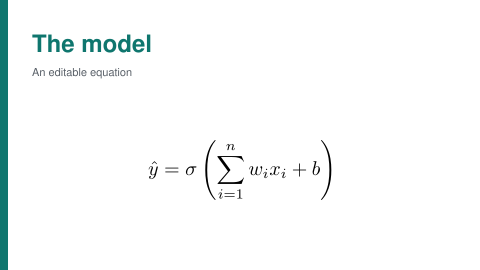

In [4]:
math = slide("The model", "An editable equation")
formula = svg.latex(r"\hat{y} = \sigma\left(\sum_{i=1}^{n} w_i x_i + b\right)", display=True)
math.add(formula.scale(2).place(WIDTH / 2, 170))
math

A list of documents saves as one slide each, and `Document.open_all` reads every slide back.

In [5]:
DECK = [cover, flow, math]
GAP, SCALE = 16, 2


def side_by_side(left: svg.Document, right: svg.Document) -> svg.Document:
    """Two slides next to each other, each rendered as pixels with a caption under it."""
    doc = svg.Document(2 * WIDTH + GAP, HEIGHT + 3 * GAP)
    doc.rect(0, 0, doc.root.get("width"), doc.root.get("height"), fill="white")
    for index, (page, caption) in enumerate(((left, "SVG"), (right, "PowerPoint, read back"))):
        x = index * (WIDTH + GAP)
        doc += svg.Image(page.rasterize(scale=SCALE), x, 0, WIDTH, HEIGHT)
        doc.text(caption, x=x + WIDTH / 2, y=HEIGHT + 2 * GAP, text_anchor="middle", font_size=14, fill="#475569")
    return doc

## A deck made in PowerPoint

`quarterly.pptx`, beside this example, was made in PowerPoint. Each slide opens as a drawing you can edit.
Next: [22 Layout](../22_layout/layout.py).

In [6]:
quarterly = svg.Document.open_all("quarterly.pptx")
print(len(quarterly), "slide(s) in quarterly.pptx")
quarterly[0]


if __name__ == "__main__":
    svg.export.save(DECK, "21_powerpoint.pptx")
    slides = svg.Document.open_all("21_powerpoint.pptx")
    print(len(slides), "slides read back")
    side_by_side(math, slides[1]).save("21_powerpoint.svg")

1 slide(s) in quarterly.pptx


3 slides read back
